In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 3)

In [ ]:
movies = [
    "Titanic", "The Matrix", "Avatar", "Inception", "Toy Story",
    "Gladiator", "Interstellar", "The Dark Knight", "Frozen", "Jurassic Park"
]

ratings = np.array([
    [5, 4, 5, 5, 1, 4, 5, 5, 1, 4],
    [5, 5, 4, 4, 2, 5, 4, 5, 5, 4],
    [1, 2, 1, 2, 5, 1, 2, 1, 5, 2],
    [4, 5, 4, 5, 1, 4, 5, 5, 4, 4],
    [2, 1, 2, 1, 5, 2, 1, 2, 5, 1]
], dtype=float)

users = ["User 1", "User 2", "User 3", "User 4", "User 5"]

movie_matrix = pd.DataFrame(ratings, index=users, columns=movies)
movie_matrix


,Titanic,The Matrix,Avatar,Inception,Toy Story,Gladiator,Interstellar,The Dark Knight,Frozen,Jurassic Park
User 1,5.0,4.0,5.0,5.0,1.0,4.0,5.0,5.0,1.0,4.0
User 2,5.0,5.0,4.0,4.0,2.0,5.0,4.0,5.0,5.0,4.0
User 3,1.0,2.0,1.0,2.0,5.0,1.0,2.0,1.0,5.0,2.0
User 4,4.0,5.0,4.0,5.0,1.0,4.0,5.0,5.0,4.0,4.0
User 5,2.0,1.0,2.0,1.0,5.0,2.0,1.0,2.0,5.0,1.0


In [ ]:
user1 = ratings[0]
user2 = ratings[1]

user1_norm = np.linalg.norm(user1)
distance_12 = np.linalg.norm(user1 - user2)

print("User 1 norm:", round(user1_norm, 3))
print("Euclidean distance between User 1 and User 2:", round(distance_12, 3))


User 1 norm: 13.229
Euclidean distance between User 1 and User 2: 4.69


In [ ]:
distance_results = []
for i in range(1, len(users)):
    distance_results.append([
        users[i],
        np.linalg.norm(user1 - ratings[i])
    ])

distance_df = pd.DataFrame(distance_results, columns=["User", "Euclidean Distance"])
distance_df.sort_values("Euclidean Distance")


,User,Euclidean Distance
2,User 4,3.464
0,User 2,4.690
3,User 5,10.630
1,User 3,10.724


In [ ]:
def cosine_similarity(a, b):
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    if denominator == 0:
        return 0.0
    return np.dot(a, b) / denominator

cosine_results = []
for i in range(1, len(users)):
    cosine_results.append([
        users[i],
        cosine_similarity(user1, ratings[i])
    ])

cosine_df = pd.DataFrame(cosine_results, columns=["User", "Cosine Similarity"])
cosine_df.sort_values("Cosine Similarity", ascending=False)


,User,Cosine Similarity
2,User 4,0.966
0,User 2,0.941
3,User 5,0.596
1,User 3,0.587


In [ ]:
def pearson_correlation(a, b):
    return np.corrcoef(a, b)[0, 1]

metric_rows = []
for i in range(1, len(users)):
    metric_rows.append([
        users[i],
        np.linalg.norm(user1 - ratings[i]),
        cosine_similarity(user1, ratings[i]),
        pearson_correlation(user1, ratings[i])
    ])

metrics_df = pd.DataFrame(
    metric_rows,
    columns=["User", "Euclidean Distance", "Cosine Similarity", "Pearson Correlation"]
)
metrics_df.sort_values("Cosine Similarity", ascending=False)


,User,Euclidean Distance,Cosine Similarity,Pearson Correlation
2,User 4,3.464,0.966,0.704
0,User 2,4.690,0.941,0.389
3,User 5,10.630,0.596,-0.890
1,User 3,10.724,0.587,-0.935


In [ ]:
cosine_matrix = np.zeros((len(users), len(users)))
for i in range(len(users)):
    for j in range(len(users)):
        cosine_matrix[i, j] = cosine_similarity(ratings[i], ratings[j])

cosine_matrix_df = pd.DataFrame(cosine_matrix, index=users, columns=users)
cosine_matrix_df


,User 1,User 2,User 3,User 4,User 5
User 1,1.000,0.941,0.587,0.966,0.596
User 2,0.941,1.000,0.757,0.984,0.774
User 3,0.587,0.757,1.000,0.711,0.943
User 4,0.966,0.984,0.711,1.000,0.693
User 5,0.596,0.774,0.943,0.693,1.000


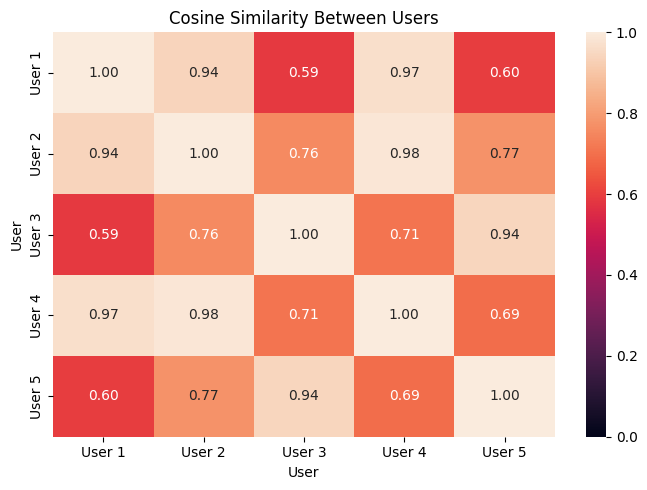

In [ ]:
plt.figure(figsize=(7, 5))
sns.heatmap(cosine_matrix_df, annot=True, fmt=".2f", vmin=0, vmax=1)
plt.title("Cosine Similarity Between Users")
plt.xlabel("User")
plt.ylabel("User")
plt.tight_layout()
plt.show()


In [ ]:
ratings_sim = ratings.copy()
ratings_sim[0, movies.index("Toy Story")] = np.nan
ratings_sim[0, movies.index("Frozen")] = np.nan

sim_df = pd.DataFrame(ratings_sim, index=users, columns=movies)
sim_df


,Titanic,The Matrix,Avatar,Inception,Toy Story,Gladiator,Interstellar,The Dark Knight,Frozen,Jurassic Park
User 1,5.0,4.0,5.0,5.0,NaN,4.0,5.0,5.0,NaN,4.0
User 2,5.0,5.0,4.0,4.0,2.0,5.0,4.0,5.0,5.0,4.0
User 3,1.0,2.0,1.0,2.0,5.0,1.0,2.0,1.0,5.0,2.0
User 4,4.0,5.0,4.0,5.0,1.0,4.0,5.0,5.0,4.0,4.0
User 5,2.0,1.0,2.0,1.0,5.0,2.0,1.0,2.0,5.0,1.0


In [ ]:
def projection_onto_vector(u, v):
    denominator = np.dot(v, v)
    if denominator == 0:
        return np.zeros_like(v)
    return (np.dot(u, v) / denominator) * v

known_mask = ~np.isnan(ratings_sim[0])
u_known = ratings_sim[0, known_mask]
v2_known = ratings[1, known_mask]

projection_u1_on_u2 = projection_onto_vector(u_known, v2_known)
projection_coefficient = np.dot(u_known, v2_known) / np.dot(v2_known, v2_known)

print("Projection coefficient of User 1 onto User 2:", round(projection_coefficient, 3))
print("First five values of the projected vector:", np.round(projection_u1_on_u2[:5], 3))


Projection coefficient of User 1 onto User 2: 1.012
First five values of the projected vector: [5.061 5.061 4.049 4.049 5.061]


In [ ]:
reference_indices = [1, 3]
reference_users = [users[i] for i in reference_indices]

known_mask = ~np.isnan(ratings_sim[0])
A = ratings[reference_indices][:, known_mask].T
b = ratings_sim[0, known_mask]

beta, residuals, rank, singular_values = np.linalg.lstsq(A, b, rcond=None)

print("Reference users:", reference_users)
print("Least-squares coefficients:")
for name, value in zip(reference_users, beta):
    print(f"  {name}: {value:.3f}")

known_prediction = A @ beta
rmse = np.sqrt(np.mean((known_prediction - b) ** 2))
print("\nRMSE on known User 1 ratings:", round(rmse, 3))


Reference users: ['User 2', 'User 4']
Least-squares coefficients:
  User 2: 0.261
  User 4: 0.761

RMSE on known User 1 ratings: 0.578


In [ ]:
missing_indices = np.where(np.isnan(ratings_sim[0]))[0]

A_missing = ratings[reference_indices][:, missing_indices].T
predicted_missing = A_missing @ beta
predicted_missing = np.clip(predicted_missing, 1, 5)

prediction_df = pd.DataFrame({
    "Movie": [movies[i] for i in missing_indices],
    "Predicted Rating": predicted_missing
}).sort_values("Predicted Rating", ascending=False)

THRESHOLD = 3.5
prediction_df["Recommendation Status"] = prediction_df["Predicted Rating"].apply(
    lambda rating: "YES (Recommended)" if rating >= THRESHOLD else "NO (Not Recommended)"
)

prediction_df

,Movie,Predicted Rating,Recommendation Status
1,Frozen,4.347,YES (Recommended)
0,Toy Story,1.282,NO (Not Recommended)


In [ ]:
import io
import zipfile
import urllib.request

ml_zip_url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

try:
    req = urllib.request.Request(ml_zip_url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=20) as response:
        zip_data = response.read()

    with zipfile.ZipFile(io.BytesIO(zip_data)) as z:
        df_ml_ratings = pd.read_csv(z.open("ml-latest-small/ratings.csv"))
        df_ml_movies = pd.read_csv(z.open("ml-latest-small/movies.csv"))

    df_ml_full = pd.merge(df_ml_ratings, df_ml_movies, on="movieId")
    print("MovieLens loaded successfully.")
    print("Ratings:", len(df_ml_full))
    print("Users:", df_ml_full["userId"].nunique())
    print("Movies:", df_ml_full["title"].nunique())

except Exception as e:
    df_ml_full = None
    print("MovieLens could not be downloaded in this environment.")
    print("The complete controlled-dataset section above is still executable.")
    print("Reason:", type(e).__name__)


MovieLens loaded successfully.
Ratings: 100836
Users: 610
Movies: 9719


In [ ]:
if df_ml_full is not None:
    N_TOP_USERS = 50
    M_TOP_MOVIES = 30

    top_user_ids = df_ml_full["userId"].value_counts().head(N_TOP_USERS).index
    top_movie_titles = df_ml_full["title"].value_counts().head(M_TOP_MOVIES).index

    df_ml_filtered = df_ml_full[
        df_ml_full["userId"].isin(top_user_ids) &
        df_ml_full["title"].isin(top_movie_titles)
    ]

    ml_pivot = df_ml_filtered.pivot(index="userId", columns="title", values="rating")
    ml_ratings = ml_pivot.to_numpy(dtype=float)
    ml_users = [f"User {uid}" for uid in ml_pivot.index]
    ml_movies = list(ml_pivot.columns)

    print(f"Reduced MovieLens matrix: {ml_ratings.shape[0]} users × {ml_ratings.shape[1]} movies")
    display(ml_pivot.head())
else:
    print("MovieLens matrix skipped because the dataset was not downloaded.")


Reduced MovieLens matrix: 50 users × 30 movies


title,Aladdin (1992),American Beauty (1999),Apollo 13 (1995),Batman (1989),Braveheart (1995),Fargo (1996),Fight Club (1999),Forrest Gump (1994),"Fugitive, The (1993)","Godfather, The (1972)",...,Seven (a.k.a. Se7en) (1995),"Shawshank Redemption, The (1994)","Silence of the Lambs, The (1991)","Sixth Sense, The (1999)",Star Wars: Episode IV - A New Hope (1977),Star Wars: Episode V - The Empire Strikes Back (1980),Star Wars: Episode VI - Return of the Jedi (1983),Terminator 2: Judgment Day (1991),Toy Story (1995),"Usual Suspects, The (1995)"
userId,,,,,,,,,,,,,,,,,,,,,
18,3.5,NaN,NaN,NaN,4.5,4.5,4.5,4.5,3.5,4.0,...,4.5,5.0,4.5,4.5,4.0,4.0,4.5,4.5,3.5,5.0
19,3.0,4.0,NaN,5.0,NaN,NaN,5.0,2.0,4.0,NaN,...,3.0,NaN,NaN,4.0,4.0,4.0,3.0,5.0,4.0,NaN
28,NaN,4.0,NaN,2.5,3.5,3.0,3.5,4.0,3.0,4.5,...,3.0,3.5,2.5,3.0,4.0,4.0,4.0,4.5,NaN,3.5
57,4.0,5.0,3.0,4.0,4.0,4.0,NaN,4.0,5.0,5.0,...,NaN,NaN,5.0,5.0,5.0,4.0,4.0,4.0,5.0,5.0
64,4.0,2.5,NaN,NaN,4.0,4.0,4.5,4.0,NaN,5.0,...,4.5,5.0,5.0,4.5,3.5,3.5,3.5,4.0,4.0,3.0


In [ ]:
def masked_cosine(a, b):
    mask = ~np.isnan(a) & ~np.isnan(b)
    if mask.sum() == 0:
        return np.nan
    a = a[mask]
    b = b[mask]
    denominator = np.linalg.norm(a) * np.linalg.norm(b)
    return np.dot(a, b) / denominator if denominator != 0 else np.nan

if df_ml_full is not None:
    target_idx = 0
    target_vector = ml_ratings[target_idx]

    ml_similarity_rows = []
    for i in range(1, len(ml_users)):
        sim = masked_cosine(target_vector, ml_ratings[i])
        ml_similarity_rows.append([ml_users[i], sim])

    ml_similarity_df = pd.DataFrame(ml_similarity_rows, columns=["User", "Cosine Similarity"])
    ml_similarity_df = ml_similarity_df.dropna().sort_values("Cosine Similarity", ascending=False)

    print("Most similar MovieLens users to the target user:")
    display(ml_similarity_df.head(10))
else:
    print("MovieLens similarity skipped.")


Most similar MovieLens users to the target user:


,User,Cosine Similarity
39,User 555,0.996
40,User 560,0.995
32,User 477,0.993
37,User 525,0.993
15,User 232,0.993
22,User 318,0.993
38,User 534,0.993
16,User 249,0.993
14,User 226,0.992
34,User 483,0.990


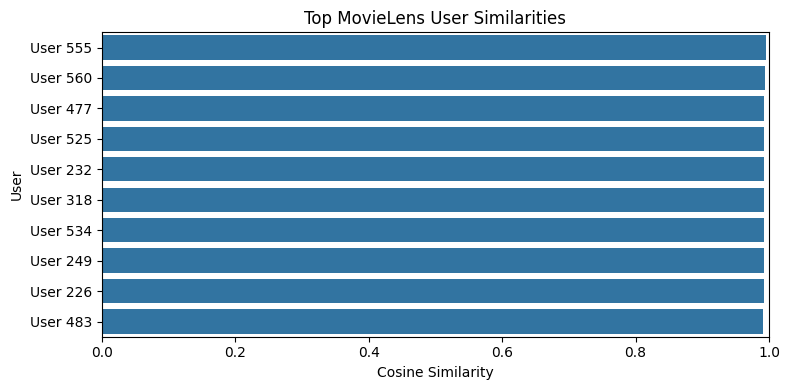

In [ ]:
if df_ml_full is not None:
    top10 = ml_similarity_df.head(10).set_index("User")
    plt.figure(figsize=(8, 4))
    sns.barplot(x=top10["Cosine Similarity"], y=top10.index)
    plt.xlim(0, 1)
    plt.title("Top MovieLens User Similarities")
    plt.xlabel("Cosine Similarity")
    plt.ylabel("User")
    plt.tight_layout()
    plt.show()
else:
    print("Plot skipped.")


In [ ]:
if df_ml_full is not None and len(ml_similarity_df) > 0:
    TOP_K_NEIGHBORS = 3
    top_similar_users = ml_similarity_df.head(TOP_K_NEIGHBORS)["User"].tolist()

    ref_indices = [ml_users.index(u) for u in top_similar_users]

    target_ratings = ml_ratings[target_idx]
    known_mask = ~np.isnan(target_ratings)
    unrated_mask = np.isnan(target_ratings)

    A_known = ml_ratings[ref_indices][:, known_mask].T
    b_known = target_ratings[known_mask]

    valid_rows = ~np.isnan(A_known).any(axis=1)

    if valid_rows.sum() > 0:
        A_clean = A_known[valid_rows]
        b_clean = b_known[valid_rows]

        beta_ml, _, _, _ = np.linalg.lstsq(A_clean, b_clean, rcond=None)

        A_unrated = ml_ratings[ref_indices][:, unrated_mask].T

        neighbor_means = np.nanmean(ml_ratings[ref_indices], axis=1, keepdims=True)
        A_unrated_filled = np.where(np.isnan(A_unrated), neighbor_means.T, A_unrated)

        predicted_ratings = A_unrated_filled @ beta_ml
        predicted_ratings = np.clip(predicted_ratings, 1.0, 5.0)

        unrated_movie_titles = [ml_movies[i] for i in np.where(unrated_mask)[0]]

        ml_recommendations_df = pd.DataFrame({
            "Movie Title": unrated_movie_titles,
            "Predicted Score": predicted_ratings
        }).sort_values("Predicted Score", ascending=False)

        ml_recommendations_df = ml_recommendations_df[ml_recommendations_df["Predicted Score"] >= 3.5]

        print(f"--- TOP MOVIELENS RECOMMENDATIONS FOR TARGET {ml_users[target_idx]} ---")
        display(ml_recommendations_df)
    else:
        print("Not enough overlapping ratings across top neighbors to solve Least Squares.")
else:
    print("Recommendation engine skipped.")

--- TOP MOVIELENS RECOMMENDATIONS FOR TARGET User 18 ---


,Movie Title,Predicted Score
0,American Beauty (1999),4.407
1,Apollo 13 (1995),3.994
2,Batman (1989),3.823
